<a href="https://colab.research.google.com/github/abhi170212/AI/blob/main/Logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Accuracy: 0.9000

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.93      0.90       100
           1       0.93      0.87      0.90       100

    accuracy                           0.90       200
   macro avg       0.90      0.90      0.90       200
weighted avg       0.90      0.90      0.90       200



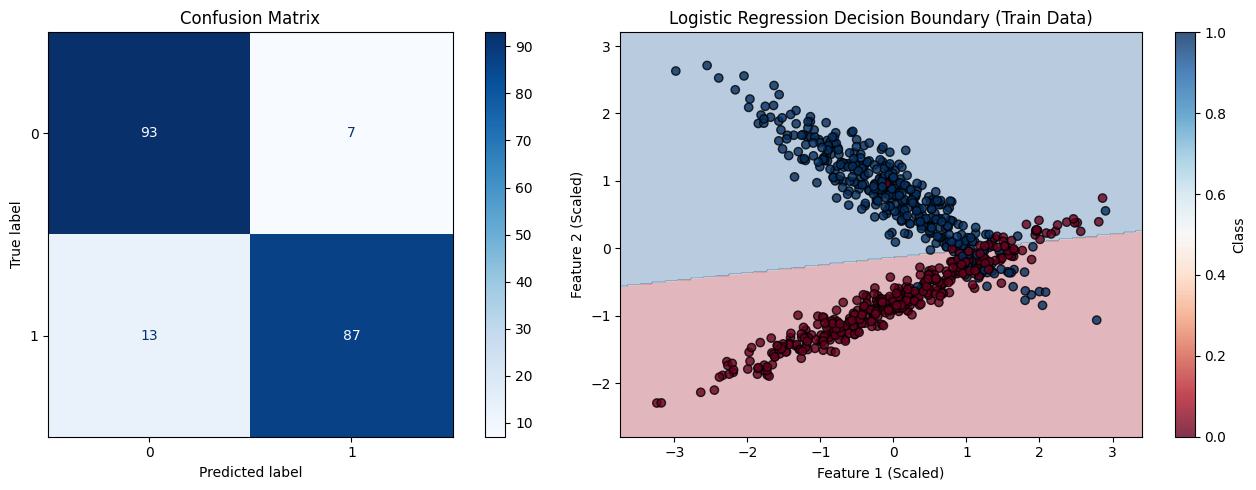

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Generate a synthetic 2D dataset for binary classification
X, y = make_classification(
    n_samples=1000,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    random_state=42,
    n_clusters_per_class=1
)

# 2. Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Scale features (essential for logistic regression convergence and regularization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Initialize and train the Logistic Regression model
# Using 'lbfgs' solver and L2 regularization by default
model = LogisticRegression(solver='lbfgs', C=1.0, random_state=42)
model.fit(X_train_scaled, y_train)

# 5. Make predictions
y_pred = model.predict(X_test_scaled)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

# 6. Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Plot Confusion Matrix
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_).plot(ax=ax[0], cmap='Blues')
ax[0].set_title("Confusion Matrix")

# 7. Plot Decision Boundary
# Create a mesh grid
x_min, x_max = X_train_scaled[:, 0].min() - 0.5, X_train_scaled[:, 0].max() + 0.5
y_min, y_max = X_train_scaled[:, 1].min() - 0.5, X_train_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

# Predict probabilities over the mesh grid
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot the contour and training points
ax[1].contourf(xx, yy, Z, alpha=0.3, cmap='RdBu')
scatter = ax[1].scatter(X_train_scaled[:, 0], X_train_scaled[:, 1], c=y_train, edgecolors='k', cmap='RdBu', alpha=0.8)
ax[1].set_title("Logistic Regression Decision Boundary (Train Data)")
ax[1].set_xlabel("Feature 1 (Scaled)")
ax[1].set_ylabel("Feature 2 (Scaled)")
fig.colorbar(scatter, ax=ax[1], label="Class")

plt.tight_layout()
plt.show()